# 02 · Who will churn? Trained on February, tested once on March

The plan ([`reports/kkbox_analysis_plan.md`](../reports/kkbox_analysis_plan.md)) fixes the
design: models are chosen and tuned on the February 2017 cohort only, then scored once on the
March 2017 cohort, the situation a deployed model faces. The March labels are read in one cell,
section 3, and nothing is changed after it.

- **Candidates:** a rule (churn if auto-renew is off or the latest payment was a cancellation),
  logistic regression, and LightGBM.
- **Primary metric:** PR-AUC on March (churn is rare, about 6%), plus ROC-AUC, Brier score,
  calibration and the share of churners in the top 5/10/20%.
- **Which model ships:** LightGBM only if its March PR-AUC beats logistic regression with a
  paired bootstrap interval that excludes zero.

| | |
|---|---|
| **Question** | Which members will churn next month? Trained on February 2017 and tested once on March, the way a deployed model is used. |
| **Answer** | LightGBM ships: PR-AUC 0.594 on March against a 9.0% base rate, clearly ahead of logistic regression (0.503) and a simple rule (0.321). Its top 10% of scores hold 60% of the members who churned. Its probabilities run low when churn rises, so calibration needs a monthly check. |
| **Next** | [Notebook 03](03_kkbox_listening.ipynb) tests whether listening data adds anything. |

In [1]:
import os
import sys
from pathlib import Path


def _root() -> Path:
    here = Path.cwd().resolve()
    for p in (here, *here.parents):
        if (p / "src" / "data" / "kkbox.py").exists():
            return p
    raise FileNotFoundError("run from inside the project folder")


ROOT = _root()
sys.path.insert(0, str(ROOT))

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss
from sklearn.model_selection import StratifiedKFold, train_test_split

from src import records
from src.churn.model import Prep, calibration_table, metrics, paired_bootstrap_pr_auc
from src.data import kkbox

con, SOURCE = kkbox.connect()
fdir = kkbox.features_dir(SOURCE)
feb = pd.read_parquet(fdir / "feb.parquet").merge(kkbox.labels(con, "feb"), on="msno")
mar = pd.read_parquet(fdir / "mar.parquet")
BOOT = int(os.environ.get("KKBOX_BOOT", "1000"))
SEED = 20261101
print(f"source: {SOURCE}; February {len(feb):,} members ({feb['is_churn'].mean():.2%} churn); March {len(mar):,} members")

source: real; February 992,931 members (6.39% churn); March 970,960 members


## 1. Tuning inside February

20% of February is set aside for the calibration decision; tuning uses 5-fold
cross-validation on the other 80%.

In [2]:
fit_df, cal_df = train_test_split(feb, test_size=0.2, stratify=feb["is_churn"], random_state=SEED)
prep = Prep().fit(fit_df)
Xl_fit, scale = prep.linear(fit_df)
Xt_fit = prep.trees(fit_df)
y_fit = fit_df["is_churn"].to_numpy()
folds = list(StratifiedKFold(5, shuffle=True, random_state=SEED).split(Xl_fit, y_fit))

LR_GRID = [0.01, 0.1, 1.0]
GBM_GRID = [dict(num_leaves=31, min_child_samples=200), dict(num_leaves=63, min_child_samples=200),
            dict(num_leaves=127, min_child_samples=500), dict(num_leaves=255, min_child_samples=1000)]
GBM_BASE = dict(n_estimators=400, learning_rate=0.05, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                reg_lambda=1.0, n_jobs=2, verbose=-1, random_state=SEED)


def cv_score(make, X):
    s = []
    for tr, va in folds:
        m = make().fit(X.iloc[tr] if hasattr(X, "iloc") else X[tr], y_fit[tr])
        s.append(average_precision_score(y_fit[va], m.predict_proba(X.iloc[va] if hasattr(X, "iloc") else X[va])[:, 1]))
    return float(np.mean(s))


cv = []
for C in LR_GRID:
    cv.append({"model": "logistic", "params": {"C": C},
               "cv_pr_auc": cv_score(lambda C=C: LogisticRegression(C=C, max_iter=500), Xl_fit)})
for g in GBM_GRID:
    cv.append({"model": "lightgbm", "params": g,
               "cv_pr_auc": cv_score(lambda g=g: lgb.LGBMClassifier(**GBM_BASE, **g), Xt_fit)})
cv = pd.DataFrame(cv)
best = cv.loc[cv.groupby("model")["cv_pr_auc"].idxmax()].set_index("model")
print(best)
cv.round(4)

                                                params  cv_pr_auc
model                                                            
lightgbm  {'num_leaves': 31, 'min_child_samples': 200}   0.574781
logistic                                    {'C': 0.1}   0.434872


,model,params,cv_pr_auc
0,logistic,{'C': 0.01},0.4339
1,logistic,{'C': 0.1},0.4349
2,logistic,{'C': 1.0},0.4349
3,lightgbm,"{'num_leaves': 31, 'min_child_samples': 200}",0.5748
4,lightgbm,"{'num_leaves': 63, 'min_child_samples': 200}",0.5746
5,lightgbm,"{'num_leaves': 127, 'min_child_samples': 500}",0.5717
6,lightgbm,"{'num_leaves': 255, 'min_child_samples': 1000}",0.5683


## 2. Final models and the calibration decision

Each model is refitted on the 80%. Isotonic calibration is kept only if it lowers the Brier
score on the held-out 20% when fitted and scored on different halves of it.

In [3]:
lr = LogisticRegression(C=best.loc["logistic", "params"]["C"], max_iter=500).fit(Xl_fit, y_fit)
gbm = lgb.LGBMClassifier(**GBM_BASE, **best.loc["lightgbm", "params"]).fit(Xt_fit, y_fit)
y_cal = cal_df["is_churn"].to_numpy()
raw_cal = {"logistic": lr.predict_proba(prep.linear(cal_df, scale)[0])[:, 1],
           "lightgbm": gbm.predict_proba(prep.trees(cal_df))[:, 1]}
calibrate, iso = {}, {}
half = np.random.default_rng(SEED).random(len(y_cal)) < 0.5
for name, p in raw_cal.items():
    gain = []
    for a, b in ((half, ~half), (~half, half)):
        f = IsotonicRegression(out_of_bounds="clip").fit(p[a], y_cal[a])
        gain.append(brier_score_loss(y_cal[b], p[b]) - brier_score_loss(y_cal[b], f.predict(p[b])))
    calibrate[name] = bool(np.mean(gain) > 0)
    iso[name] = IsotonicRegression(out_of_bounds="clip").fit(p, y_cal) if calibrate[name] else None
print("isotonic calibration kept:", calibrate)


def score(name, df):
    p = lr.predict_proba(prep.linear(df, scale)[0])[:, 1] if name == "logistic" else gbm.predict_proba(prep.trees(df))[:, 1]
    return iso[name].predict(p) if iso[name] is not None else p


def rule(df):
    return ((df["auto_renew"].fillna(0) == 0) | (df["last_cancel"].fillna(0) == 1)).astype(float).to_numpy()

isotonic calibration kept: {'logistic': True, 'lightgbm': False}


## 3. The one look at March

In [4]:
mar = mar.merge(kkbox.labels(con, "mar"), on="msno")          # March labels read here, once
y_mar = mar["is_churn"].to_numpy()
p_mar = {"rule": rule(mar), "logistic": score("logistic", mar), "lightgbm": score("lightgbm", mar)}
results = pd.DataFrame({k: metrics(y_mar, v) for k, v in p_mar.items()}).T
results.loc["base rate", "pr_auc"] = y_mar.mean()
boot = paired_bootstrap_pr_auc(y_mar, p_mar["lightgbm"], p_mar["logistic"], n=BOOT, seed=SEED)
ship = "lightgbm" if boot["ci"][0] > 0 else "logistic"
print(f"March churn {y_mar.mean():.2%}. LightGBM minus logistic PR-AUC {boot['diff']:+.4f} "
      f"[{boot['ci'][0]:+.4f}, {boot['ci'][1]:+.4f}] -> ships: {ship}")
results.round(4)

March churn 8.99%. LightGBM minus logistic PR-AUC +0.0918 [+0.0896, +0.0942] -> ships: lightgbm


,pr_auc,roc_auc,brier,capture_5,capture_10,capture_20
rule,0.3212,0.7841,0.1037,0.2490,0.4978,0.6755
logistic,0.5025,0.8456,0.0595,0.3700,0.5636,0.7400
lightgbm,0.5943,0.8625,0.0544,0.4106,0.6037,0.7350
base rate,0.0899,NaN,NaN,NaN,NaN,NaN


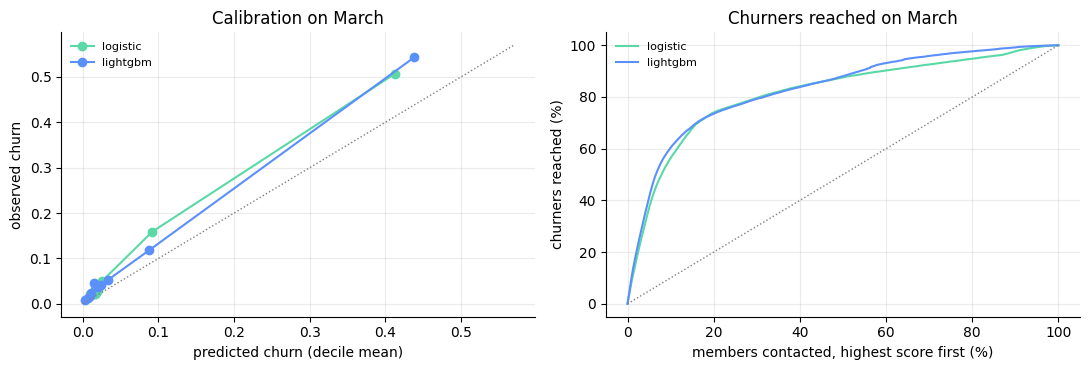

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for name, col in (("logistic", "#5AD8A6"), ("lightgbm", "#5B8FF9")):
    t = calibration_table(y_mar, p_mar[name])
    axes[0].plot(t["predicted"], t["observed"], "o-", color=col, label=name)
    order = np.argsort(-p_mar[name])
    axes[1].plot(np.arange(1, len(order) + 1) / len(order) * 100, np.cumsum(y_mar[order]) / y_mar.sum() * 100,
                 color=col, label=name)
lim = [0, max(axes[0].get_xlim()[1], axes[0].get_ylim()[1])]
axes[0].plot(lim, lim, ":", color="#7F7F7F", lw=1)
axes[0].set(xlabel="predicted churn (decile mean)", ylabel="observed churn", title="Calibration on March")
axes[1].plot([0, 100], [0, 100], ":", color="#7F7F7F", lw=1)
axes[1].set(xlabel="members contacted, highest score first (%)", ylabel="churners reached (%)",
            title="Churners reached on March")
for ax in axes:
    ax.legend(frameon=False, fontsize=8)
    ax.grid(alpha=0.25)
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
records.save_figure(fig, "02_kkbox_churn_model.png", SOURCE)

**How to read the figure.** Left (calibration): each point is a tenth of members, grouped by predicted churn; a well-calibrated model sits on the diagonal. Points above it mean more members churned than predicted, which is what happens when churn rises from February to March. Right (gains): if you contact members from the highest score down, how many of the churners you reach. A steeper curve is a better ranking; the top 10% reaching about 60% of churners is what makes a targeted campaign affordable.

## 4. Diagnostics: what drives the scores, where the model is weaker, what moved

Added after the plan's primary analysis (dated note in the plan): they explain and stress-test
the model, and none of them changes which model ships. Their results go to a separate record,
`02b_kkbox_model_diagnostics.json`.

**What drives the scores (SHAP).** LightGBM's own TreeSHAP contributions, exact and on the
log-odds scale, for a random 20,000 March members: how far each feature moves each member's
score from the average. Mean |SHAP| ranks the features; for numeric features, the rank
correlation between a feature's value and its contribution says which way it pushes.

In [6]:
from src.churn.model import psi

rng = np.random.default_rng(SEED)
sample = np.sort(rng.choice(len(mar), size=min(20_000, len(mar)), replace=False))
Xs = prep.trees(mar.iloc[sample])
contrib = pd.DataFrame(gbm.predict(Xs, pred_contrib=True)[:, :-1], columns=Xs.columns, index=Xs.index)
shap_rank = contrib.abs().mean().sort_values(ascending=False)
direction = {c: float(pd.Series(Xs[c].astype(float)).corr(contrib[c], method="spearman"))
             for c in shap_rank.index if c in kkbox.NUMERIC and Xs[c].nunique() > 1}
shap_table = pd.DataFrame({"mean_abs_shap": shap_rank, "share": shap_rank / shap_rank.sum(),
                           "value_vs_push": pd.Series(direction)}).reindex(shap_rank.index).head(10)   # keep the ranking
shap_table.round(3)

,mean_abs_shap,share,value_vs_push
auto_renew,0.523,0.252,-0.561
payment_method,0.286,0.138,NaN
list_price,0.177,0.085,0.751
tenure_days,0.166,0.080,0.444
reg_days,0.122,0.059,-0.163
days_to_expiry,0.113,0.054,0.880
paid,0.097,0.047,0.732
n_tx_90,0.094,0.045,-0.601
last_cancel,0.089,0.043,0.167
n_tx_365,0.084,0.040,-0.730


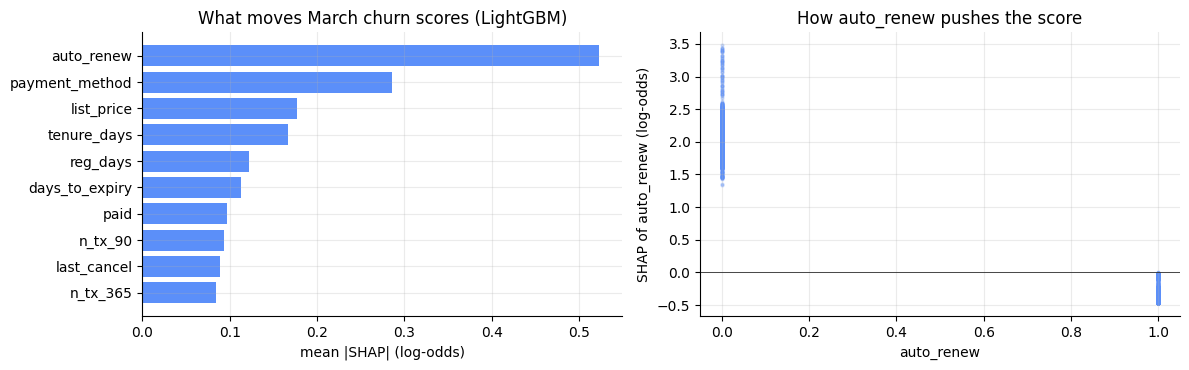

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
top = shap_table.index[::-1]
axes[0].barh(top, shap_table.loc[top, "mean_abs_shap"], color="#5B8FF9")
axes[0].set(xlabel="mean |SHAP| (log-odds)", title="What moves March churn scores (LightGBM)")
lead = next(c for c in shap_table.index if c in direction)
axes[1].scatter(Xs[lead].astype(float), contrib[lead], s=4, alpha=0.25, color="#5B8FF9")
axes[1].axhline(0, color="#2B2B2B", lw=0.6)
axes[1].set(xlabel=lead, ylabel=f"SHAP of {lead} (log-odds)", title=f"How {lead} pushes the score")
for ax in axes:
    ax.grid(alpha=0.25)
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
records.save_figure(fig, "02b_kkbox_shap.png", SOURCE)
plt.show()

**How to read the figure.** Left: the features that move scores most, on average, for March
members. Right: for the leading numeric feature, each dot is a member; above zero the feature
raises that member's churn score, below zero it lowers it. Flat bands mean the feature acts like
a switch; a slope means its effect grows with its value.

**Where the model is weaker (segments).** The shipped score on March, within the segments a
retention team would act on, plus gender, which the model uses as a feature: churn rate, mean
predicted churn (calibration within the segment) and PR-AUC against the segment's own base rate.
Segments with fewer than 2,000 members or 50 churners are left out.

In [8]:
p_ship = p_mar[ship]
num = mar[["plan_days", "auto_renew", "tenure_days"]].astype(float)   # nullable integers from DuckDB -> NaN
plan = np.where(num["plan_days"].isna(), "no prior payment", np.where(num["plan_days"] <= 31, "monthly", "longer"))
renew = num["auto_renew"].map({1.0: "on", 0.0: "off"}).fillna("no prior payment").to_numpy()
tenure = pd.cut(num["tenure_days"] / 30.4, [-np.inf, 3, 12, 24, np.inf],
                labels=["under 3 months", "3-12 months", "12-24 months", "24+ months"]).astype(object).fillna("no prior payment").to_numpy()
SEGMENTS = {"auto-renew": renew, "plan": plan, "tenure": tenure, "gender": mar["gender"].fillna("unknown").to_numpy(),
            "registered via": mar["registered_via"].fillna("missing").astype(str).to_numpy()}
rows = []
for seg, values in SEGMENTS.items():
    for level in pd.unique(values):
        m = values == level
        if m.sum() < 2000 or y_mar[m].sum() < 50:
            continue
        rows.append({"segment": seg, "level": str(level), "members": int(m.sum()), "churn": float(y_mar[m].mean()),
                     "mean_predicted": float(p_ship[m].mean()),
                     "pr_auc": float(average_precision_score(y_mar[m], p_ship[m]))})
segments = pd.DataFrame(rows)
segments["pr_auc_lift"] = segments["pr_auc"] / segments["churn"]
segments["predicted_minus_observed"] = segments["mean_predicted"] - segments["churn"]
segments.set_index(["segment", "level"]).round(3)

members  churn  mean_predicted  pr_auc  \
segment        level                                                      
auto-renew     on                 853954  0.045           0.029   0.338   
               off                114482  0.414           0.325   0.736   
               no prior payment     2524  0.547           0.339   0.637   
plan           monthly            944368  0.070           0.053   0.470   
               longer              24068  0.827           0.505   0.900   
               no prior payment     2524  0.547           0.339   0.637   
tenure         3-12 months        215509  0.082           0.066   0.549   
               24+ months         314069  0.084           0.051   0.516   
               12-24 months       357272  0.088           0.062   0.652   
               under 3 months      81586  0.129           0.116   0.630   
               no prior payment     2524  0.547           0.339   0.637   
gender         unknown            582055  0.064           0.049   0.554   
               male               204561  0.129           0.089   0.618   
               female             184344  0.130           0.088   0.623   
registered via 7                  462684  0.045           0.028   0.446   
               9                  235689  0.127           0.088   0.639   
               3                  106459  0.172           0.129   0.602   
               missing            109993  0.053           0.048   0.520   
               4                   52744  0.231           0.184   0.622   
               13                   3391  0.099           0.086   0.522   

                                 pr_auc_lift  predicted_minus_observed  
segment        level                                                    
auto-renew     on                      7.485                    -0.016  
               off                     1.778                    -0.089  
               no prior payment        1.165                    -0.208  
plan           monthly                 6.727                    -0.017  
               longer                  1.088                    -0.322  
               no prior payment        1.165                    -0.208  
tenure         3-12 months             6.710                    -0.016  
               24+ months              6.152                    -0.033  
               12-24 months            7.410                    -0.026  
               under 3 months          4.870                    -0.013  
               no prior payment        1.165                    -0.208  
gender         unknown                 8.718                    -0.015  
               male                    4.788                    -0.040  
               female                  4.799                    -0.041  
registered via 7                       9.963                    -0.016  
               9                       5.040                    -0.039  
               3                       3.493                    -0.044  
               missing                 9.723                    -0.005  
               4                       2.690                    -0.047  
               13                      5.279                    -0.013

**How to read the table.** `pr_auc_lift` is PR-AUC divided by the segment's churn rate: how much
better than picking members at random within that segment the ranking is. A low lift means the
model can tell little apart inside that group (often because the segment itself is the signal,
as with auto-renew). `predicted_minus_observed` below zero is under-prediction; the overall
February-to-March drift shows up in every segment, so look for segments where it is much larger.

**What moved between February and March (drift).** Population stability index of every
feature, and of the shipped model's score, from the February training members to the March
members. Under 0.1 is stable, 0.1 to 0.25 a moderate shift, over 0.25 a large one. The score
itself is checked on February's held-out 20% against March.

In [9]:
drift = pd.Series({c: psi(feb[c].astype(float), mar[c].astype(float)) for c in kkbox.NUMERIC}
                  | {c: psi(feb[c].astype(str), mar[c].astype(str)) for c in kkbox.CATEGORICAL}).sort_values(ascending=False)
score_psi = psi(pd.Series(score(ship, cal_df)), pd.Series(p_ship))
print(f"score PSI (February held-out vs March): {score_psi:.3f}; "
      f"{int((drift > 0.25).sum())} features shift strongly, {int(drift.between(0.1, 0.25).sum())} moderately")
drift.head(8).round(3)

score PSI (February held-out vs March): 0.030; 2 features shift strongly, 3 moderately


tenure_days       0.697
n_tx_30           0.476
days_to_expiry    0.217
n_tx_total        0.156
n_tx_365          0.129
n_tx_90           0.017
list_price        0.013
reg_days          0.003
dtype: float64

In [10]:
diagnostics = {"shap_sample": int(len(sample)), "shap_top10": shap_table.reset_index(names="feature").to_dict(orient="records"),
               "segments": segments.to_dict(orient="records"), "psi_features": drift.to_dict(), "psi_score": score_psi}
print("wrote", records.write("02b_kkbox_model_diagnostics", diagnostics, SOURCE).name)
worst = segments.sort_values("pr_auc_lift").iloc[0]
print(f"Top SHAP feature: {shap_table.index[0]} ({shap_table['share'].iloc[0]:.0%} of mean |SHAP|). "
      f"Weakest segment by lift: {worst['segment']} = {worst['level']} (PR-AUC {worst['pr_auc']:.3f} at "
      f"{worst['churn']:.1%} churn). Score PSI {score_psi:.3f}; largest feature shift {drift.index[0]} "
      f"({drift.iloc[0]:.3f}).")

wrote 02b_kkbox_model_diagnostics.json
Top SHAP feature: auto_renew (25% of mean |SHAP|). Weakest segment by lift: plan = longer (PR-AUC 0.900 at 82.7% churn). Score PSI 0.030; largest feature shift tenure_days (0.697).


In [11]:
gain = pd.Series(gbm.booster_.feature_importance("gain"), index=Xt_fit.columns).sort_values(ascending=False)
importance = (gain / gain.sum()).head(10)
pd.DataFrame({"msno": mar["msno"], "p_churn": p_mar[ship], "is_churn": y_mar}).to_parquet(fdir / "mar_scores.parquet", index=False)
record = {"feb_members": int(len(feb)), "feb_churn": float(feb["is_churn"].mean()), "mar_members": int(len(mar)),
          "mar_churn": float(y_mar.mean()), "cv": cv.assign(params=cv["params"].astype(str)).to_dict(orient="records"),
          "chosen": {k: best.loc[k, "params"] for k in best.index}, "calibrated": calibrate,
          "march": results.drop(index="base rate").to_dict(orient="index"), "lightgbm_minus_logistic": boot,
          "ships": ship, "importance_top10": importance.to_dict()}
print("wrote", records.write("02_kkbox_churn_model", record, SOURCE).name)
m = results.loc[ship]
print(f"On March, the {ship} model reaches PR-AUC {m['pr_auc']:.3f} against a {y_mar.mean():.1%} base rate "
      f"(ROC-AUC {m['roc_auc']:.3f}); the top 10% of scores hold {m['capture_10']:.0%} of churners. "
      f"The rule reaches PR-AUC {results.loc['rule', 'pr_auc']:.3f}.")

wrote 02_kkbox_churn_model.json
On March, the lightgbm model reaches PR-AUC 0.594 against a 9.0% base rate (ROC-AUC 0.863); the top 10% of scores hold 60% of churners. The rule reaches PR-AUC 0.321.


## 5. Experiment tracking in MLflow

Every candidate from the tuning grid (its cross-validated PR-AUC on February) and both final
models (their one-look March metrics and the fitted model) are logged as MLflow runs, and the
model that ships is registered as `kkbox_churn` with the alias `@production`, so a scoring job
loads it by name (`models:/kkbox_churn@production`) instead of from a file path. The model takes
the feature frame built by `Prep.trees`; LightGBM was not recalibrated (section 2), so its raw
probabilities are the ones scored here. To browse the runs, from the project root:
`mlflow ui --backend-store-uri sqlite:///mlflow.db`.

In [12]:
from src.models.tracking import log_run, register_production_model

EXPERIMENT = f"kkbox_churn_{SOURCE}"
tags = {"data": SOURCE, "train": "February 2017", "test": "March 2017"}
for r in cv.itertuples():
    log_run(EXPERIMENT, f"cv_{r.model}", params={"model": r.model, "folds": 5, **r.params},
            metrics={"cv_pr_auc": r.cv_pr_auc}, tags={**tags, "stage": "tuning"})
final_params = {"logistic": {"C": best.loc["logistic", "params"]["C"], "max_iter": 500},
                "lightgbm": {**GBM_BASE, **best.loc["lightgbm", "params"]}}
run_ids = {name: log_run(EXPERIMENT, f"final_{name}",
                         params={"model": name, "isotonic_calibration": calibrate[name], **final_params[name]},
                         metrics={f"march_{k}": v for k, v in results.loc[name].items()},
                         tags={**tags, "stage": "final", "ships": name == ship}, model=model)
           for name, model in (("logistic", lr), ("lightgbm", gbm))}
if run_ids[ship] is None:
    print("MLflow is not installed: runs were not logged")
else:
    if SOURCE == "real":
        register_production_model(run_ids[ship], "kkbox_churn", quiet=True)
    print(f"logged {len(cv) + 2} runs to MLflow experiment '{EXPERIMENT}'"
          + (f"; {ship} registered as kkbox_churn@production" if SOURCE == "real" else ""))

logged 9 runs to MLflow experiment 'kkbox_churn_real'; lightgbm registered as kkbox_churn@production


## Takeaways

- **The model ranks well on a month it never saw:** PR-AUC 0.594, about 6.6 times the base rate.
- **LightGBM earns its place** over logistic regression by a margin whose interval excludes zero, as the plan required.
- **Watch calibration:** the ranking holds up, but predicted probabilities run low when churn rises; recalibrate monthly before using them in money calculations.

**Next:** [notebook 03](03_kkbox_listening.ipynb), does listening add anything?